<a href="https://colab.research.google.com/github/night-marionette/Pneumonia-Triage/blob/main/Model2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

=== Simulation Results (Pneumonia Share = 25%, CAP = 60 mins) ===
         pneu_avg  pneu_95  missed_avg  missed_max  norm_avg
FIFO         98.6    148.2        24.1        25.1      98.7
SCORE        13.0     48.4        23.2        24.9     128.7
CAP          79.0    142.4        27.6        28.6     105.3
PERFECT       9.1     27.3         2.3         2.5     128.2


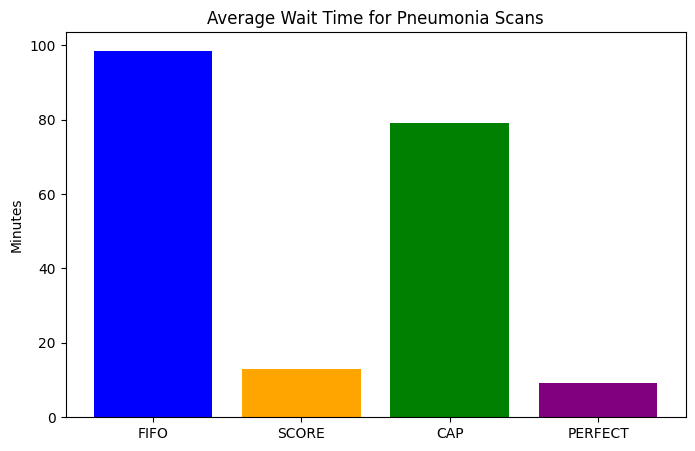

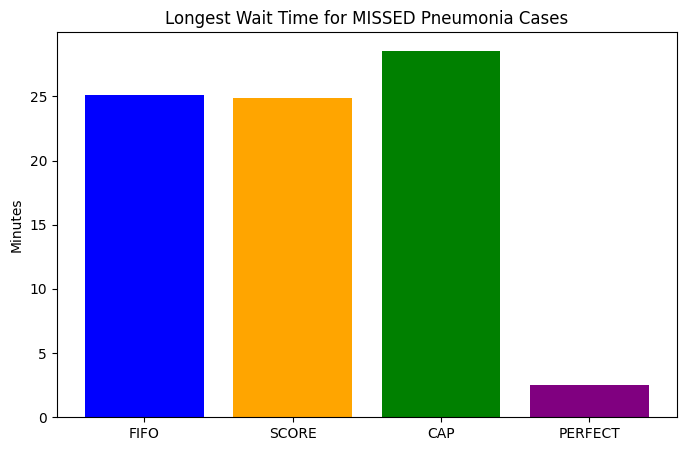

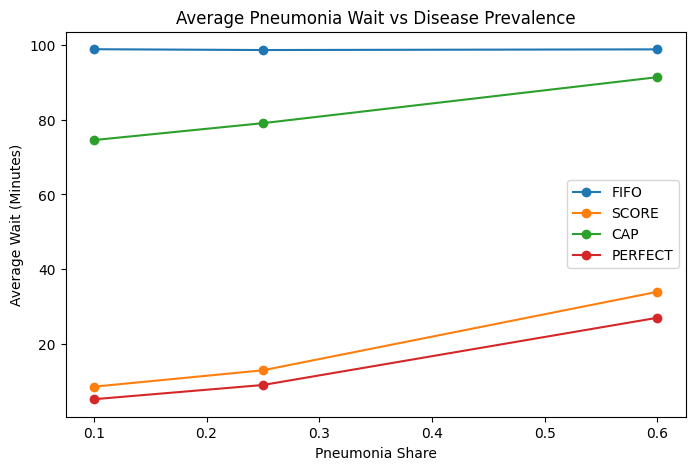


=== CAP Test (Rule C) ===
   CAP  Pneu Avg Wait  Missed Max Wait  Normal Avg Wait
0   30           87.8             26.6            102.4
1   60           79.0             28.6            105.3
2  120           55.8             32.3            113.4


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ==========================================
# 1. PARAMETERS
# ==========================================
ARRIVAL_MEAN_MIN = 5
READ_MEAN_MIN = 4.5
BACKLOG = 30
SHIFT_MIN = 480
CAP_MIN = 60
N_RUNS = 500
THRESHOLD = 0.5
PNEUMONIA_SHARE = 0.25

# Load the data (make sure the file is uploaded to Colab and named exactly test_scores.csv)
df = pd.read_csv('test_scores.csv')

# ==========================================
# 2. SIMULATION FUNCTION
# ==========================================
def simulate(run_seed, rule, pneu_share=PNEUMONIA_SHARE, cap=CAP_MIN):
    np.random.seed(run_seed)

    # Sample scans based on share
    total_scans = int(SHIFT_MIN / ARRIVAL_MEAN_MIN) + BACKLOG
    n_pneu = int(total_scans * pneu_share)
    n_norm = total_scans - n_pneu

    pneu_df = df[df['true_label'] == 1].sample(n=n_pneu, replace=True, random_state=run_seed)
    norm_df = df[df['true_label'] == 0].sample(n=n_norm, replace=True, random_state=run_seed)
    scans = pd.concat([pneu_df, norm_df]).sample(frac=1, random_state=run_seed).reset_index(drop=True)

    # Arrival times & Reading times
    arrival_times = np.zeros(len(scans))
    arrival_times[BACKLOG:] = np.cumsum(np.random.exponential(ARRIVAL_MEAN_MIN, len(scans) - BACKLOG))
    read_times = np.random.exponential(READ_MEAN_MIN, len(scans))

    unread = set(scans.index)
    doctor_free_time = 0
    wait_times = []

    while unread:
        # Find arrived scans
        available = [i for i in unread if arrival_times[i] <= doctor_free_time]

        if not available:
            next_arrival = min([arrival_times[i] for i in unread])
            doctor_free_time = next_arrival
            continue

        # The 4 Rules
        if rule == 'FIFO':
            chosen = min(available, key=lambda i: arrival_times[i])
        elif rule == 'SCORE':
            chosen = max(available, key=lambda i: scans.loc[i, 'score'])
        elif rule == 'CAP':
            over_cap = [i for i in available if doctor_free_time - arrival_times[i] > cap]
            if over_cap:
                chosen = min(over_cap, key=lambda i: arrival_times[i])
            else:
                chosen = max(available, key=lambda i: scans.loc[i, 'score'])
        elif rule == 'PERFECT':
            chosen = max(available, key=lambda i: scans.loc[i, 'true_label'])

        wait = doctor_free_time - arrival_times[chosen]
        wait_times.append({
            'true_label': scans.loc[chosen, 'true_label'],
            'score': scans.loc[chosen, 'score'],
            'wait_time': wait,
            'missed': (scans.loc[chosen, 'true_label'] == 1) and (scans.loc[chosen, 'score'] < THRESHOLD)
        })

        unread.remove(chosen)
        doctor_free_time += read_times[chosen]

    return pd.DataFrame(wait_times)

# Helper to run multiple times and average
def run_experiment(rule, pneu_share=PNEUMONIA_SHARE, cap=CAP_MIN):
    results = []
    for seed in range(N_RUNS):
        res_df = simulate(seed, rule, pneu_share, cap)
        pneu = res_df[res_df['true_label'] == 1]
        missed = res_df[res_df['missed']]
        norm = res_df[res_df['true_label'] == 0]

        results.append({
            'pneu_avg': pneu['wait_time'].mean(),
            'pneu_95': pneu['wait_time'].quantile(0.95),
            'missed_avg': missed['wait_time'].mean() if len(missed) > 0 else 0,
            'missed_max': missed['wait_time'].max() if len(missed) > 0 else 0,
            'norm_avg': norm['wait_time'].mean()
        })
    return pd.DataFrame(results).mean()

# ==========================================
# 3. RUN MAIN SIMULATION (25% Share)
# ==========================================
rules = ['FIFO', 'SCORE', 'CAP', 'PERFECT']
main_results = {rule: run_experiment(rule) for rule in rules}
results_df = pd.DataFrame(main_results).T

print("=== Simulation Results (Pneumonia Share = 25%, CAP = 60 mins) ===")
print(results_df.round(1))

# ==========================================
# 4. GENERATE CHARTS
# ==========================================
# Chart 1: Average Wait for Pneumonia
plt.figure(figsize=(8, 5))
plt.bar(results_df.index, results_df['pneu_avg'], color=['blue', 'orange', 'green', 'purple'])
plt.title('Average Wait Time for Pneumonia Scans')
plt.ylabel('Minutes')
plt.show()

# Chart 2: Longest Wait for Missed Cases
plt.figure(figsize=(8, 5))
plt.bar(results_df.index, results_df['missed_max'], color=['blue', 'orange', 'green', 'purple'])
plt.title('Longest Wait Time for MISSED Pneumonia Cases')
plt.ylabel('Minutes')
plt.show()

# Chart 3: Lines across Pneumonia Share
shares = [0.10, 0.25, 0.60]
share_results = {rule: [] for rule in rules}
for share in shares:
    for rule in rules:
        res = run_experiment(rule, pneu_share=share)
        share_results[rule].append(res['pneu_avg'])

plt.figure(figsize=(8, 5))
for rule in rules:
    plt.plot(shares, share_results[rule], marker='o', label=rule)
plt.title('Average Pneumonia Wait vs Disease Prevalence')
plt.xlabel('Pneumonia Share')
plt.ylabel('Average Wait (Minutes)')
plt.legend()
plt.show()

# ==========================================
# 5. CAP TESTS (30, 60, 120)
# ==========================================
print("\n=== CAP Test (Rule C) ===")
caps = [30, 60, 120]
cap_data = []
for c in caps:
    res = run_experiment('CAP', cap=c)
    cap_data.append({
        'CAP': c,
        'Pneu Avg Wait': res['pneu_avg'],
        'Missed Max Wait': res['missed_max'],
        'Normal Avg Wait': res['norm_avg']
    })
cap_df = pd.DataFrame(cap_data)
print(cap_df.round(1))